# 00 - Understanding Dataset 1 (EMSCAD fake job postings)

This notebook is for **learning what is in the data** before any modeling. Run it top to bottom, and read the "What to look for" notes between cells. At the end there is a short list of questions to answer in your own words; those answers become the Data Overview section of the report.

**How it is organised**
1. **Orientation** (whole dataset): shape, columns, target, overall missingness. Nothing here compares fraud against legitimate postings.
2. **Duplicates and the split**: we group near-duplicate postings and freeze a train/test split. The test rows are then set aside.
3. **Profiling** (train split only): how fraud and legitimate postings differ, field by field.

Why the split comes before the comparisons: anything you notice by comparing the classes will influence your feature choices. If you noticed it using the test rows, the test set is no longer an honest check. So class comparisons use the training rows only.

Run this from the `notebooks/` folder after the data is in `data/raw/d1/`.

In [2]:
import sys
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold

try:
    from IPython.display import display
except ImportError:
    display = print

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 80)

# Paths: find the project folder by looking upward for a data/raw folder,
# so this works wherever the notebook is opened from.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
for folder in (PROCESSED_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42

print("Project folder:", ROOT)
print("CSV files found in data/raw:", [p.name for p in RAW_DIR.glob("*.csv")])

Project folder: /Users/sunxinyang/Documents/bt4012-fake-job-fraud
CSV files found in data/raw: ['fake_job_postings.csv']


The next cell defines the helper functions used below (loading, duplicate grouping, the split, the structural flags). They are included here so this notebook is self-contained. You can skip reading them for now and come back when you want to see exactly how a step works.

In [3]:
# Helper functions. You do not need to read these now: they are the same logic as src/d1.py,
# included here so this notebook needs nothing except the CSV and the installed packages.
TARGET = "fraudulent"
TEXT_COLS = ["title", "company_profile", "description", "requirements", "benefits"]
BINARY_COLS = ["telecommuting", "has_company_logo", "has_questions"]
CAT_COLS = ["employment_type", "required_experience", "required_education", "industry", "function"]


def load_d1():
    files = sorted(RAW_DIR.glob("*.csv"))
    if not files:
        raise FileNotFoundError(f"No CSV found in {RAW_DIR}. Put fake_job_postings.csv there.")
    df = pd.read_csv(files[0])
    if TARGET not in df.columns:
        raise ValueError(f"Expected a '{TARGET}' column, found: {list(df.columns)}")
    if "job_id" not in df.columns:
        df.insert(0, "job_id", np.arange(len(df)))
    return df


def add_text_all(df):
    """Join all free-text fields. `text_clean` also replaces masked contact details
    such as '#URL_8e4c...#' with a fixed token so unique hashes do not look like words."""
    out = df.copy()
    out["text_all"] = out[TEXT_COLS].fillna("").astype(str).agg(" ".join, axis=1)
    out["text_clean"] = out["text_all"].str.replace(
        r"#(URL|EMAIL|PHONE)_[A-Za-z0-9]+#", lambda m: f" {m.group(1).lower()}ph ", regex=True)
    return out


def add_country(df):
    """`location` looks like 'US, NY, New York'; the first token is the country."""
    out = df.copy()
    country = out["location"].fillna("").str.split(",").str[0].str.strip().str.upper()
    out["country"] = country.replace("", "UNK")
    return out


def dedup_groups(df, threshold=0.9, chunk=500):
    """Link postings whose TF-IDF cosine similarity is >= threshold; connected components = groups."""
    norm = df["text_clean"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
    vec = TfidfVectorizer(stop_words="english", max_df=0.5, min_df=2, sublinear_tf=True, dtype=np.float32)
    X = vec.fit_transform(norm)
    XT = X.T.tocsr()
    n = X.shape[0]
    rows, cols = [], []
    for start in range(0, n, chunk):
        S = (X[start:start + chunk] @ XT).tocoo()
        keep = (S.data >= threshold) & (S.row + start < S.col)
        rows.append(S.row[keep] + start)
        cols.append(S.col[keep])
    rows = np.concatenate(rows)
    cols = np.concatenate(cols)
    graph = sparse.coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(n, n))
    _, labels = connected_components(graph, directed=False)
    return labels


def dedup_report(df):
    sizes = df.groupby("group_id").size()
    in_multi = df["group_id"].map(sizes) > 1
    conflicts = df.groupby("group_id")[TARGET].nunique()
    return pd.Series({
        "rows": len(df),
        "groups": int(sizes.size),
        "rows_in_duplicate_groups": int(in_multi.sum()),
        "share_rows_in_duplicate_groups": round(float(in_multi.mean()), 3),
        "largest_group": int(sizes.max()),
        "groups_with_label_conflict": int((conflicts > 1).sum()),
        "fraud_rows_in_duplicate_groups": int((in_multi & df[TARGET].eq(1)).sum()),
    })


def make_split(df, test_size=0.2, seed=SEED):
    """Stratified, group-aware train/test split."""
    sgkf = StratifiedGroupKFold(n_splits=int(round(1 / test_size)), shuffle=True, random_state=seed)
    _, test_idx = next(sgkf.split(df, df[TARGET], groups=df["group_id"]))
    split = np.full(len(df), "train", dtype=object)
    split[test_idx] = "test"
    return pd.Series(split, index=df.index, name="split")


def save_split(df):
    path = PROCESSED_DIR / "d1_split.csv"
    df[["job_id", "group_id", "split", "country"]].to_csv(path, index=False)
    return path


def add_structural_flags(df):
    """Domain-motivated boolean signals. Requires `text_all`."""
    f = pd.DataFrame(index=df.index)
    f["no_company_profile"] = df["company_profile"].isna()
    f["no_company_logo"] = df["has_company_logo"].eq(0)
    f["no_screening_questions"] = df["has_questions"].eq(0)
    f["telecommuting"] = df["telecommuting"].eq(1)
    f["has_salary_range"] = df["salary_range"].notna()
    for col in ["requirements", "benefits", "department", "industry", "function",
                "employment_type", "required_experience", "required_education"]:
        f[f"missing_{col}"] = df[col].isna()
    f["has_url_placeholder"] = df["text_all"].str.contains("#URL_", regex=False)
    f["has_email_placeholder"] = df["text_all"].str.contains("#EMAIL_", regex=False)
    f["has_phone_placeholder"] = df["text_all"].str.contains("#PHONE_", regex=False)
    f["has_exclamation"] = df["text_all"].str.contains("!", regex=False)
    f["title_all_caps"] = df["title"].fillna("").str.isupper()
    return f.astype(bool)


# Bundle everything under the name `d1` so the cells below read the same as in the project code.
d1 = SimpleNamespace(
    TARGET=TARGET, TEXT_COLS=TEXT_COLS, BINARY_COLS=BINARY_COLS, CAT_COLS=CAT_COLS,
    load_d1=load_d1, add_text_all=add_text_all, add_country=add_country,
    dedup_groups=dedup_groups, dedup_report=dedup_report, make_split=make_split,
    save_split=save_split, add_structural_flags=add_structural_flags,
)

d1.D1_DIR = RAW_DIR
print("CSV files found:", [p.name for p in RAW_DIR.glob("*.csv")])

CSV files found: ['fake_job_postings.csv']


## 1. Orientation (whole dataset)

### What is one row?
One row is **one job posting**. The columns fall into four kinds:

| Column | Kind | Meaning |
|---|---|---|
| `job_id` | identifier | Row id. Not a feature. |
| `title` | text | Job title |
| `company_profile` | text | The company's self-description |
| `description` | text | The job description |
| `requirements` | text | Required skills or qualifications |
| `benefits` | text | Offered benefits |
| `location` | structured string | Usually `country, state, city` (for example `US, NY, New York`) |
| `department` | category | Department name (free text) |
| `salary_range` | string | Usually `min-max` as text |
| `employment_type`, `required_experience`, `required_education`, `industry`, `function` | category | Dropdown-style fields |
| `telecommuting`, `has_company_logo`, `has_questions` | binary (0/1) | Remote work allowed, logo shown, screening questions attached |
| `fraudulent` | **target** (0/1) | 1 = fraudulent posting |

In [4]:
df = d1.load_d1()
raw_cols = list(df.columns)                      # remember the original columns
feature_cols = [c for c in raw_cols if c not in ("job_id", d1.TARGET)]
print("rows, columns:", df.shape)

overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1),
})
overview

rows, columns: (17880, 18)


,dtype,n_unique,n_missing,pct_missing
job_id,int64,17880,0,0.0
title,str,11231,0,0.0
location,str,3105,346,1.9
department,str,1337,11547,64.6
salary_range,str,874,15012,84.0
company_profile,str,1709,3308,18.5
description,str,14801,1,0.0
requirements,str,11967,2696,15.1
benefits,str,6204,7212,40.3
telecommuting,int64,2,0,0.0


**What to look for**
- Do the column names and count match the table above? If not, note what is different before continuing.
- Which columns are almost entirely missing? A field that is missing for 70% of rows is still informative, but in a different way (see section 4).
- `n_unique` for text columns is close to the row count; for categories it is small. Which category columns have a surprisingly large number of distinct values (a sign of free text)?

In [5]:
def show(row, width=300):
    """Print one posting field by field, truncating long text."""
    for col in raw_cols:
        val = "" if pd.isna(row[col]) else str(row[col]).replace("\n", " ")
        print(f"{col:22s}: {val[:width]}")

print("One arbitrary posting (row 0):\n")
show(df.iloc[0])

One arbitrary posting (row 0):

job_id                : 1
title                 : Marketing Intern
location              : US, NY, New York
department            : Marketing
salary_range          : 
company_profile       : We're Food52, and we've created a groundbreaking and award-winning cooking site. We support, connect, and celebrate home cooks, and give them everything they need in one place.We have a top editorial, business, and engineering team. We're focused on using technology to find new and better ways to co
description           : Food52, a fast-growing, James Beard Award-winning online food community and crowd-sourced and curated recipe hub, is currently interviewing full- and part-time unpaid interns to work in a small team of editors, executives, and developers in its New York City headquarters.Reproducing and/or repackagi
requirements          : Experience with content management systems a major plus (any blogging counts!)Familiar with the Food52 editorial voice and aest

### The target

fraudulent
0    17014
1      866

Fraud rate: 4.84%
Accuracy of a model that always says 'legitimate': 95.16%


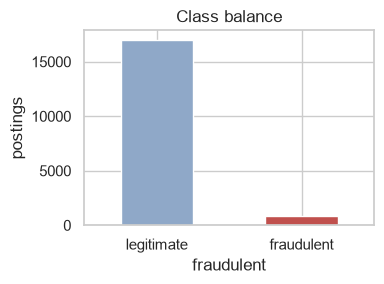

In [6]:
counts = df[d1.TARGET].value_counts().sort_index()
rate = df[d1.TARGET].mean()
print(counts.to_string())
print(f"\nFraud rate: {rate:.2%}")
print(f"Accuracy of a model that always says 'legitimate': {1 - rate:.2%}")

ax = counts.rename({0: "legitimate", 1: "fraudulent"}).plot.bar(color=["#8fa8c8", "#c0504d"], rot=0, figsize=(4, 3))
ax.set_ylabel("postings")
ax.set_title("Class balance")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_class_balance.png", dpi=200)
plt.show()

**Think about it:** a model that never flags anything scores very high accuracy. That is why this project reports precision, recall and PR-AUC for the fraud class instead of accuracy.

## 2. Duplicates and the frozen split

Job boards often repost the same ad for several locations. If copies of one posting land in both training and test data, the model is partly tested on things it has already seen, and scores look better than they really are. So we group near-duplicates (TF-IDF cosine similarity >= 0.9) and keep each group on one side of every split.

This step takes a minute or so.

In [7]:
df = d1.add_country(d1.add_text_all(df))
df["group_id"] = d1.dedup_groups(df, threshold=0.9)
display(d1.dedup_report(df).to_frame("value"))

,value
rows,17880.00
groups,12417.00
rows_in_duplicate_groups,7325.00
share_rows_in_duplicate_groups,0.41
largest_group,417.00
groups_with_label_conflict,5.00
fraud_rows_in_duplicate_groups,406.00


In [8]:
sizes = df.groupby("group_id").size().sort_values(ascending=False)
big = sizes.head(8).index
(df[df["group_id"].isin(big)]
   .groupby("group_id")
   .agg(size=("job_id", "size"), fraud_rate=(d1.TARGET, "mean"),
        distinct_locations=("location", "nunique"), example_title=("title", "first"))
   .sort_values("size", ascending=False))

,size,fraud_rate,distinct_locations,example_title
group_id,,,,
34,417,0.0,387,English Teacher Abroad
9,157,0.0,76,Customer Service Associate - Part Time
35,144,0.0,143,Graduates: English Teacher Abroad
526,74,0.0,45,Beauty & Fragrance consultants needed
873,52,0.0,2,"International Broadcaster, Sango Language"
73,47,0.0,41,Edinburgh Fragrance and Beauty Promotional Staff
429,46,0.0,46,Graduates: English Teacher Abroad (Conversational)
117,42,0.0,42,English Teacher Abroad (Conversational)


In [9]:
# 1. How many *independent* fraud examples do you really have?
fraud = df[df.fraudulent == 1]
print("fraud rows:", len(fraud), "| distinct fraud groups:", fraud.group_id.nunique())
print(fraud.groupby("group_id").size().sort_values(ascending=False).head(10))
print("\n")

# 2. The 5 groups with conflicting labels
conf = df.groupby("group_id").fraudulent.nunique()
print(df[df.group_id.isin(conf[conf > 1].index)][["group_id", "title", "location", "fraudulent"]].sort_values("group_id"))

print("\n")
# 3. Do the "English Teacher Abroad" variants share a company profile?
big = [34, 35, 429, 117]
sub = df[df.group_id.isin(big)]
print(sub.groupby("group_id").company_profile.nunique())
print(sub.company_profile.value_counts().head())

fraud rows: 866 | distinct fraud groups: 571
group_id
2613    22
1162    21
1415    21
2622    21
5970    20
2938    19
7368    11
6473    10
4511    10
5847     9
dtype: int64


       group_id                                      title                location  fraudulent
1658       1379                                 Data Entry           US, FL, miami           0
1746       1379                                 Data Entry    US, PA, ACADEMY LIFE           0
17650      1379                                 Data Entry   US, FL, HILLIARD FL             1
4520       1379                                 Data Entry       US, MI, ACME MI             0
1823       1515                                 Data Entry  US, WA, ARDENVOIR WA             0
1922       1515                                 Data entry      US, TX, Fort Worth           1
2977       1515  Administrative Assistant/Customer Service       US, CA, San diego           1
17744      3306              Required Assistant Accountant   

In [10]:
import difflib

g = df[df.group_id == 1379]

# 1. All original columns, one posting per column, full text (no truncation)
view = g[raw_cols].T
view.columns = [f"row {i} (fraud={g.loc[i, 'fraudulent']})" for i in g.index]
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(view)

# 2. Which columns differ at all?
same = g[raw_cols].astype(str).nunique() <= 1
print("Columns identical across all rows :", list(same[same].index))
print("Columns that differ               :", list(same[~same].index))

# 3. Word-level diff: first legit row vs the fraud row
fraud_idx = g.index[g.fraudulent == 1][0]
legit_idx = g.index[g.fraudulent == 0][0]
print(f"\nWord-level diff, legit row {legit_idx} -> fraud row {fraud_idx}")
for col in ["title", "company_profile", "description", "requirements", "benefits"]:
    a = str(g.loc[legit_idx, col]).split()
    b = str(g.loc[fraud_idx, col]).split()
    if a == b:
        print(f"  {col}: identical")
        continue
    print(f"  {col}:")
    for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(None, a, b).get_opcodes():
        if tag != "equal":
            print(f"    {tag}: legit={' '.join(a[i1:i2])!r}  fraud={' '.join(b[j1:j2])!r}")

,row 1658 (fraud=0),row 1746 (fraud=0),row 4520 (fraud=0),row 17650 (fraud=1)
job_id,1659,1747,4521,17651
title,Data Entry,Data Entry,Data Entry,Data Entry
location,"US, FL, miami","US, PA, ACADEMY LIFE","US, MI, ACME MI","US, FL, HILLIARD FL"
department,NaN,NaN,NaN,NaN
salary_range,NaN,NaN,NaN,25-30
company_profile,NaN,NaN,NaN,NaN
description,"Prepares source data for computer entry by compiling and sorting information; establishing entry priorities. •Processes customer and account source documents by reviewing data for deficiencies; resolving discrepancies by using standard procedures or returning incomplete documents to the team leader for resolution.•Enters customer and account data by inputting alphabetic and numeric information on keyboard or optical scanner according to screen format. •Maintains data entry requirements by following data program techniques and procedures. •Verifies entered customer and account data by reviewing, correcting, deleting, or reentering data; combining data from both systems when account information is incomplete; purging files to eliminate duplication of data. •Tests customer and account system changes and upgrades by inputting new data; reviewing output. •Secures information by completing data base backups. ayobamijegsonmoney: Maintains operations by following policies and procedures; reporting needed changes. •Maintains customer confidence and protects operations by keeping information confidential. •Contributes to team effort by accomplishing related results as needed.","•Prepares source data for computer entry by compiling and sorting information; establishing entry priorities. •Processes customer and account source documents by reviewing data for deficiencies; resolving discrepancies by using standard procedures or returning incomplete documents to the team leader for resolution.•Enters customer and account data by inputting alphabetic and numeric information on keyboard or optical scanner according to screen format. •Maintains data entry requirements by following data program techniques and procedures. •Verifies entered customer and account data by reviewing, correcting, deleting, or reentering data; combining data from both systems when account information is incomplete; purging files to eliminate duplication of data. •Tests customer and account system changes and upgrades by inputting new data; reviewing output. •Secures information by completing data base backups. ayobamijegsonmoney: Maintains operations by following policies and procedures; reporting needed changes. •Maintains customer confidence and protects operations by keeping information confidential. •Contributes to team effort by accomplishing related results as needed.","•Prepares source data for computer entry by compiling and sorting information; establishing entry priorities. •Processes customer and account source documents by reviewing data for deficiencies; resolving discrepancies by using standard procedures or returning incomplete documents to the team leader for resolution.•Enters customer and account data by inputting alphabetic and numeric information on keyboard or optical scanner according to screen format. •Maintains data entry requirements by following data program techniques and procedures. •Verifies entered customer and account data by reviewing, correcting, deleting, or reentering data; combining data from both systems when account information is incomplete; purging files to eliminate duplication of data. •Tests customer and account system changes and upgrades by inputting new data; reviewing output. •Secures information by completing data base backups. ayobamijegsonmoney: Maintains operations by following policies and procedures; reporting needed changes. •Maintains customer confidence and protects operations by keeping information confidential. •Contributes to team effort by accomplishing related results as needed.","Prepares source data for computer entry by compiling and sorting information; establishing

Columns identical across all rows : ['title', 'department', 'salary_range', 'company_profile', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function']
Columns that differ               : ['job_id', 'location', 'description', 'requirements', 'benefits', 'telecommuting', 'fraudulent']

Word-level diff, legit row 1658 -> fraud row 17650
  title: identical
  company_profile: identical
  description:
    replace: legit='data. •Tests'  fraud='d Tests'
    delete: legit='ayobamijegsonmoney:'  fraud=''
  requirements:
    replace: legit='Skills/Qualifications: Organization, Typing,'  fraud='We are seeking extremely motivated and experienced individual for position of'
    replace: legit='Skills, Attention to Detail, Confidentiality, Thoroughness, Decision Making, Independence, Analyzing Information, Results Driven, Energy Level'  fraud='clerk/Administartive Asistance/Customer Service/Receiptionist/Pay roll office ..Position: 

In [11]:
g = df[df.group_id == 1379]
fraud_idx = g.index[g.fraudulent == 1][0]
legit_idx = g.index[g.fraudulent == 0][0]

def jaccard(a, b):
    a = set(str(a).lower().split()) if pd.notna(a) else set()
    b = set(str(b).lower().split()) if pd.notna(b) else set()
    return len(a & b) / max(len(a | b), 1)

cols = ["title", "company_profile", "description", "requirements", "benefits"]
sim = pd.DataFrame(
    [[jaccard(df.loc[legit_idx, cl], df.loc[fraud_idx, cf]) for cf in cols] for cl in cols],
    index=[f"legit.{c}" for c in cols], columns=[f"fraud.{c}" for c in cols],
).round(2)
with pd.option_context("display.width", 250, "display.max_columns", 20):
    display(sim)

,fraud.title,fraud.company_profile,fraud.description,fraud.requirements,fraud.benefits
legit.title,1.00,0.0,0.02,0.04,0.00
legit.company_profile,0.00,0.0,0.00,0.00,0.00
legit.description,0.02,0.0,0.95,0.05,0.02
legit.requirements,0.10,0.0,0.04,0.03,0.00
legit.benefits,0.04,0.0,0.05,0.96,0.12


In [12]:
g = df[df.group_id ==  1515 ]
fraud_idx = g.index[g.fraudulent == 1][0]
legit_idx = g.index[g.fraudulent == 0][0]

def jaccard(a, b):
    a, b = set(str(a).lower().split()), set(str(b).lower().split())
    return len(a & b) / max(len(a | b), 1)

cols = ["title", "company_profile", "description", "requirements", "benefits"]
sim = pd.DataFrame(
    [[jaccard(df.loc[legit_idx, cl], df.loc[fraud_idx, cf]) for cf in cols] for cl in cols],
    index=[f"legit.{c}" for c in cols], columns=[f"fraud.{c}" for c in cols],
).round(2)
with pd.option_context("display.width", 250, "display.max_columns", 20):
    display(sim)

,fraud.title,fraud.company_profile,fraud.description,fraud.requirements,fraud.benefits
legit.title,1.00,0.0,0.02,0.10,0.00
legit.company_profile,0.00,1.0,0.00,0.00,0.00
legit.description,0.02,0.0,0.78,0.04,0.01
legit.requirements,0.10,0.0,0.03,0.86,0.00
legit.benefits,0.00,0.0,0.01,0.00,0.47


In [13]:
import difflib

def show_diff(i, j, cols=("title", "description", "requirements", "benefits")):
    for col in cols:
        a = str(df.loc[i, col]).split() if pd.notna(df.loc[i, col]) else []
        b = str(df.loc[j, col]).split() if pd.notna(df.loc[j, col]) else []
        if a == b:
            print(f"{col}: identical")
            continue
        print(f"{col}:")
        for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(None, a, b, autojunk=False).get_opcodes():
            if tag != "equal":
                print(f"   {tag}: A={' '.join(a[i1:i2])[:250]!r}\n          B={' '.join(b[j1:j2])[:250]!r}")

print("=== legit 1823 (A) vs fraud 1922 (B) ===")
show_diff(1823, 1922)
print("\n=== fraud 1922 (A) vs fraud 2977 (B) ===")
show_diff(1922, 2977)

=== legit 1823 (A) vs fraud 1922 (B) ===
title:
   replace: A='Entry'
          B='entry'
description:
   replace: A='•Prepares'
          B='Data Entry ClerkData Entry Clerk Job Purpose: Maintains database by entering new and updated customer and account information.Data Entry Clerk Job Duties:Prepares'
   replace: A='•Processes'
          B='Processes'
   replace: A='resolution.•Enters'
          B='resolution. Enters'
   replace: A='•Maintains'
          B='Maintains'
   replace: A='•Verifies'
          B='Verifies'
   replace: A='•Tests'
          B='Tests'
   replace: A='•Secures'
          B='Secures'
   delete: A='ayobamijegsonmoney:'
          B=''
   replace: A='•Maintains'
          B='Maintains'
   replace: A='•Contributes'
          B='Contributes'
requirements:
   replace: A='Information,'
          B='Information ,'
benefits:
   delete: A='Benefits:'
          B=''
   replace: A='#URL_c801649eeb4007728c8f41b2d6629d92c2295ff77e1f2d401d7696ce3569db63#'
          B='plans. P

In [14]:
import re

url_pat = re.compile(r"#URL_([A-Za-z0-9]+)#")
urls = df["text_all"].apply(lambda t: set(url_pat.findall(t)))
exploded = (df[["job_id", "group_id", "fraudulent"]].assign(url=urls)
              .explode("url").dropna(subset=["url"]))
per_url = (exploded.groupby("url")
           .agg(n_postings=("job_id", "nunique"), n_groups=("group_id", "nunique"),
                fraud_rate=("fraudulent", "mean"))
           .sort_values("n_postings", ascending=False))
display(per_url.head(15))
print("URLs shared by >=2 postings:", int((per_url.n_postings >= 2).sum()),
      "| of which span >=2 text-groups:", int((per_url.n_groups >= 2).sum()))

target = "c801649eeb4007728c8f41b2d6629d92c2295ff77e1f2d401d7696ce3569db63"
display(df[df.text_all.str.contains(target, regex=False)][["group_id", "title", "location", "fraudulent"]])

,n_postings,n_groups,fraud_rate
url,,,
75db76d58f7994c7db24e8998c2fc953ab9a20ea9ac948b217693963f78d2e6b,617,11,0.000000
ed9094c60184b8a4975333957f05be37e69d3cdb68decc9dd9a4242733cfd7f7,617,11,0.000000
ec64af2b4fe2ca316e828f93b0cd098c22f8beba98dcac09d4dd7384b221a5e8,504,191,0.000000
2954b76adf23051d4bc35fc729f5a18c5de715ed82dfaee24b3aabbf3874ca57,255,39,0.000000
9753a54b28303bf636a2816399b9c255d76fabb791336a4c748da2611a23264f,247,182,0.000000
01a736d89d2f0b19de700923d2c312837e180465650804d0f84105352812bf9a,151,136,0.019868
968b3a839b798052f33a95a811f8b2366cd66f6bcc98f2885bea5ee47d000659,145,123,0.000000
8d92932a488fb7e172d73a0f6813d06d464f1f03705d2825f86b2c7947d60a86,111,94,0.009009
c66532ffa1ce76ab447da6774719060c42c584edbf44d74cdb94fc4ac219ca45,108,96,0.000000


URLs shared by >=2 postings: 732 | of which span >=2 text-groups: 621


,group_id,title,location,fraudulent
1823,1515,Data Entry,"US, WA, ARDENVOIR WA",0
1843,1532,Customer Service Representative,"US, TX, Houston",1
4003,3243,Customer Service,"US, ,",0
4052,1532,Administrative Assitstant,"US, NY, New York",1
4565,1532,Customer Service Rep,"US, PA, Philadelphia",1
5306,4215,Administrative Assistant/Front Desk Clerk,"US, , San Antonio",0
6294,4999,Data Entry,"US, ,",0
7353,5763,Data Entry,"US, AL, califonia",1
11537,8426,Human Resources Administrator,"US, GA, Suwanee",0
15199,10821,Bookkeeper,"US, DC,",1


In [15]:
import re
from scipy import sparse
from scipy.sparse.csgraph import connected_components

url_pat = re.compile(r"#URL_([A-Za-z0-9]+)#")

def combined_groups(df, url_cap=None, use_profile=True, min_profile_len=50):
    df = df.reset_index(drop=True)
    n = len(df)
    rows, cols = [], []

    def add_links(labels, valid=None):
        idx = np.arange(len(labels))
        first = pd.Series(idx).groupby(labels).transform("min").to_numpy()
        keep = np.ones(len(idx), dtype=bool) if valid is None else valid
        rows.append(idx[keep]); cols.append(first[keep])

    add_links(df["group_id"].to_numpy())                      # text-similarity groups

    if use_profile:                                           # identical, specific company profile
        prof = (df["company_profile"].fillna("").str.replace("&amp;", "&", regex=False)
                  .str.lower().str.replace(r"\s+", " ", regex=True).str.strip())
        ok = (prof.str.len() >= min_profile_len).to_numpy()
        add_links(prof.where(ok).astype("category").cat.codes.to_numpy(), valid=ok)

    if url_cap:                                               # shared masked URL, only if not too common
        ex = (pd.DataFrame({"pos": np.arange(n), "url": df["text_all"].apply(lambda t: set(url_pat.findall(t)))})
                .explode("url").dropna(subset=["url"]))
        size = ex.groupby("url")["pos"].transform("nunique")
        ex = ex[(size >= 2) & (size <= url_cap)]
        rows.append(ex["pos"].to_numpy())
        cols.append(ex.groupby("url")["pos"].transform("min").to_numpy())

    r, c = np.concatenate(rows), np.concatenate(cols)
    g = sparse.coo_matrix((np.ones(len(r)), (r, c)), shape=(n, n))
    return connected_components(g, directed=False)[1]

settings = {
    "text only":                 dict(use_profile=False),
    "+ profile":                 dict(),
    "+ profile + URL cap 10":    dict(url_cap=10),
    "+ profile + URL cap 30":    dict(url_cap=30),
    "+ profile + URL cap 100":   dict(url_cap=100),
    "+ profile + URL no cap":    dict(url_cap=10**9),
}
y = df["fraudulent"].to_numpy()
out = []
for name, kw in settings.items():
    gid = combined_groups(df, **kw)
    sizes = pd.Series(gid).value_counts()
    out.append({
        "setting": name,
        "groups": sizes.size,
        "largest_group": int(sizes.iloc[0]),
        "distinct_fraud_groups": int(pd.Series(gid)[y == 1].nunique()),
        "label_conflict_groups": int((pd.Series(y).groupby(gid).nunique() > 1).sum()),
    })
with pd.option_context("display.width", 200, "display.max_columns", 10):
    display(pd.DataFrame(out).set_index("setting"))

,groups,largest_group,distinct_fraud_groups,label_conflict_groups
setting,,,,
text only,12417,417,571,5
+ profile,4440,674,414,5
+ profile + URL cap 10,4284,674,391,6
+ profile + URL cap 30,4132,1596,357,7
+ profile + URL cap 100,3978,4231,352,5
+ profile + URL no cap,3788,5632,348,5


**What to look for**
- What share of rows belong to a duplicate group? Is it a small or a large part of the data?
- Do the biggest groups look like genuine reposts (same title, different location)? If a group looks like unrelated postings, the similarity threshold may be too loose.
- `groups_with_label_conflict` counts groups whose copies are labelled both real and fake. Any such group is label noise. Write the number down.

In [16]:
if "group_id_text" not in df.columns:
    df["group_id_text"] = df["group_id"]       # text-only version, kept for the sensitivity analysis
df["group_id"] = combined_groups(df.assign(group_id=df["group_id_text"]))   # text similarity + identical company profile
display(d1.dedup_report(df).to_frame("value"))

big = df["group_id"].value_counts().index[0]
print("largest group:", int((df.group_id == big).sum()), "rows | fraud rate:", df.loc[df.group_id == big, d1.TARGET].mean())

rest = df[df.group_id != big]
split = d1.make_split(rest, test_size=0.2, seed=SEED)
df["split"] = "train"
df.loc[rest.index, "split"] = split
df[["job_id", "group_id", "group_id_text", "split", "country"]].to_csv(PROCESSED_DIR / "d1_split.csv", index=False)
display(pd.crosstab(df["split"], df[d1.TARGET], margins=True))

train = df[df["split"] == "train"].reset_index(drop=True)
print(f"\ntrain rows: {len(train)} | fraud postings in train: {int(train[d1.TARGET].sum())}")
print("fraud groups by split:", df[df.fraudulent == 1].groupby("split").group_id.nunique().to_dict())
print("largest group is in:", df.loc[df.group_id == df.group_id.value_counts().index[0], "split"].iloc[0])

,value
rows,17880.00
groups,4440.00
rows_in_duplicate_groups,14839.00
share_rows_in_duplicate_groups,0.83
largest_group,674.00
groups_with_label_conflict,5.00
fraud_rows_in_duplicate_groups,538.00


largest group: 674 rows | fraud rate: 0.0


fraudulent,0,1,All
split,,,
test,3268,173,3441
train,13746,693,14439
All,17014,866,17880



train rows: 14439 | fraud postings in train: 693
fraud groups by split: {'test': 83, 'train': 331}
largest group is in: train


In [17]:
out_cols = raw_cols + ["group_id", "group_id_text", "country"]

train_df = df.loc[df["split"] == "train", out_cols]
test_df = df.loc[df["split"] == "test", out_cols]

train_df.to_csv(PROCESSED_DIR / "d1_train.csv", index=False)
test_df.to_csv(PROCESSED_DIR / "d1_test.csv", index=False)

# Re-read both files from disk and confirm the test set really is held out
tr = pd.read_csv(PROCESSED_DIR / "d1_train.csv")
te = pd.read_csv(PROCESSED_DIR / "d1_test.csv")
assert len(tr) + len(te) == len(df), "rows lost or duplicated"
assert set(tr.job_id).isdisjoint(te.job_id), "same posting in train and test"
assert set(tr.group_id).isdisjoint(te.group_id), "a group straddles train and test"
assert list(tr.columns) == list(te.columns) == out_cols
assert tr.fraudulent.sum() + te.fraudulent.sum() == df.fraudulent.sum()
print(f"train: {tr.shape} | fraud {int(tr.fraudulent.sum())} ({tr.fraudulent.mean():.2%}) | groups {tr.group_id.nunique()}")
print(f"test : {te.shape} | fraud {int(te.fraudulent.sum())} ({te.fraudulent.mean():.2%}) | groups {te.group_id.nunique()}")
print("overlap of job_id:", len(set(tr.job_id) & set(te.job_id)), "| overlap of group_id:", len(set(tr.group_id) & set(te.group_id)))

train: (14439, 21) | fraud 693 (4.80%) | groups 3555
test : (3441, 21) | fraud 173 (5.03%) | groups 885
overlap of job_id: 0 | overlap of group_id: 0


**From here on only `train` is used.** The test rows are never looked at again until the final evaluation.

## 3. Profiling the training split

### 3.1 Missingness by class
A missing field is often a signal in itself: a genuine employer usually fills in the company profile, while a scammer may not bother.

fraudulent,legit,fraud,gap_fraud_minus_legit
company_profile,0.158,0.661,0.503
required_experience,0.413,0.479,0.066
benefits,0.376,0.429,0.053
employment_type,0.197,0.250,0.052
required_education,0.467,0.499,0.032
location,0.020,0.023,0.003
description,0.000,0.001,0.001
title,0.000,0.000,0.000
telecommuting,0.000,0.000,0.000
has_company_logo,0.000,0.000,0.000


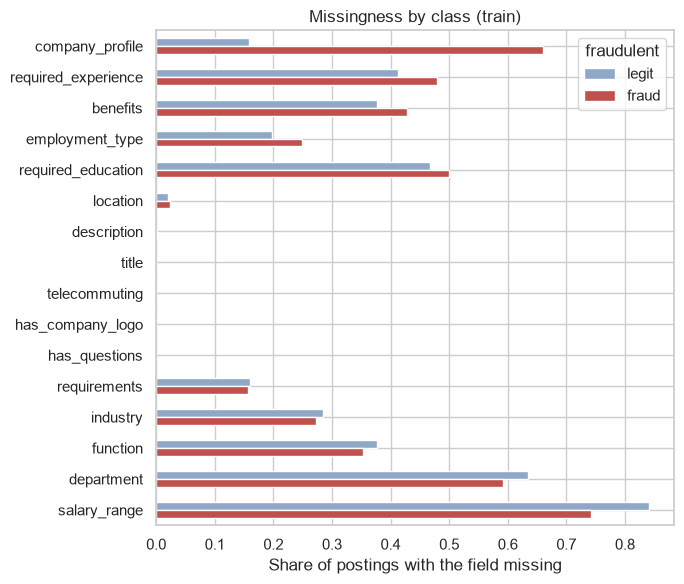

In [18]:
miss = (train[feature_cols].isna().groupby(train[d1.TARGET]).mean().T
          .rename(columns={0: "legit", 1: "fraud"}))
miss["gap_fraud_minus_legit"] = miss["fraud"] - miss["legit"]
miss = miss.sort_values("gap_fraud_minus_legit", ascending=False)
display(miss.round(3))

ax = miss[["legit", "fraud"]].plot.barh(figsize=(7, 6), color=["#8fa8c8", "#c0504d"])
ax.invert_yaxis()
ax.set_xlabel("Share of postings with the field missing")
ax.set_title("Missingness by class (train)")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_missingness_by_class.png", dpi=200)
plt.show()

**What to look for**
- Which fields have the biggest gap between the classes, and in which direction?
- Is a field missing for most legitimate postings too? Then missingness there tells you little.
- Keep in mind these are *associations*. A field can differ between classes simply because both classes were collected differently.

### 3.2 Text fields: how long, how often empty

In [19]:
rows = []
for col in d1.TEXT_COLS:
    s = train[col].fillna("")
    words = s.str.split().str.len()
    for label, name in [(0, "legit"), (1, "fraud")]:
        m = (train[d1.TARGET] == label).to_numpy()
        rows.append({"field": col, "class": name,
                     "pct_empty": round((words[m] == 0).mean() * 100, 1),
                     "median_words_when_present": words[m & (words > 0).to_numpy()].median()})
display(pd.DataFrame(rows).pivot(index="field", columns="class", values=["pct_empty", "median_words_when_present"]))

pct_empty       median_words_when_present       
class               fraud legit                     fraud  legit
field                                                           
benefits             42.9  37.7                      32.0   33.0
company_profile      66.1  15.8                      98.0   99.0
description           0.3   0.0                     119.0  144.0
requirements         15.7  16.0                      49.0   72.0
title                 0.0   0.0                       3.0    3.0

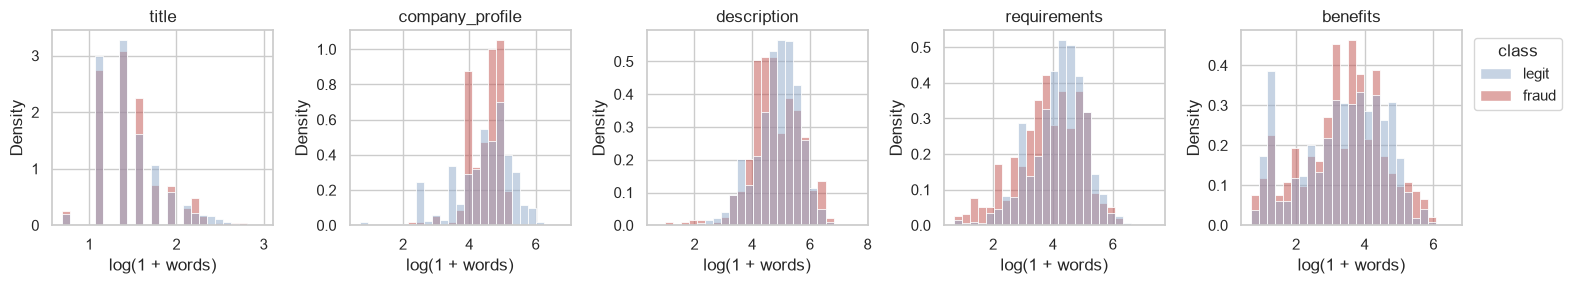

In [20]:
fig, axes = plt.subplots(1, len(d1.TEXT_COLS), figsize=(3.2 * len(d1.TEXT_COLS), 3), sharey=False)
for ax, col in zip(axes, d1.TEXT_COLS):
    words = train[col].fillna("").str.split().str.len()
    plot_df = pd.DataFrame({"log_words": np.log1p(words[words > 0]), "class": train.loc[words > 0, d1.TARGET].map({0: "legit", 1: "fraud"})})
    sns.histplot(data=plot_df, x="log_words", hue="class", stat="density", common_norm=False, bins=25, ax=ax,
                 palette={"legit": "#8fa8c8", "fraud": "#c0504d"}, legend=(col == d1.TEXT_COLS[-1]))
    ax.set_title(col)
    ax.set_xlabel("log(1 + words)")
sns.move_legend(axes[-1], "upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_text_lengths.png", dpi=200, bbox_inches="tight")
plt.show()

**What to look for**
- Do fraud postings tend to have shorter or longer descriptions? Is the difference big, or do the two histograms overlap almost completely?
- Length alone is a weak signal when the distributions overlap a lot. Note which fields show a visible shift.

### 3.3 Read some postings
Numbers hide a lot. Read a few real examples from each class.

In [21]:
for label, name in [(1, "FRAUDULENT"), (0, "LEGITIMATE")]:
    for _, r in train[train[d1.TARGET] == label].sample(3, random_state=SEED).iterrows():
        print(f"=== {name} | title: {r['title']} | location: {r['location']}")
        print(str(r["description"])[:500].replace("\n", " "))
        print()

=== FRAUDULENT | title: Recruitment & Talent Acquisition Professional | location: US, CA, San Francisco
We are looking for top ranked Technical Recruiters to join our network of trusted Recruiting &amp; Talent Acquisition Professionals. Approved members of the network will be ranked and reviewed by previous Hiring Managers and/or candidates of whom they have placed, providing transparency and regulation to the talent acquisition process.  Upon Approval, Recruiters will be listed on the network outlining your strengths, geographical preferences and area of focus and will then be paired up with Star

=== FRAUDULENT | title: Agency Sales Managers $150-$175,000/yr | location: US, NY, Oneonta
We provide No Credit Check Financing to customers of Small and Medium size Businesses and can help 90% of the industries from Auto Mechanics to Dentists and Lawyers.We are seeking skilled Account Managers to grow with us and help us achieve our goals in this new and exciting industry.This is designed a

**What to look for:** write down two or three things that make the fraudulent examples feel different (tone, vagueness, what they ask for, what they leave out). These are your first hypotheses. They are only impressions from a handful of examples, so treat them as ideas to test later, not as findings.

### 3.4 Categorical fields
Fraud *rate* is the share of postings in a category that are fraudulent. Compare it with the overall train rate shown below, and pay attention to the `n` column: a high rate on 12 postings means little.

In [22]:
base_rate = train[d1.TARGET].mean()
print(f"overall train fraud rate: {base_rate:.2%}\n")

def rate_table(col, min_n=30, top=8):
    t = (train.groupby(col, dropna=False)[d1.TARGET]
              .agg(n="size", fraud_n="sum", fraud_rate="mean"))
    t = t[t["n"] >= min_n].sort_values("n", ascending=False).head(top)
    return t.round(3)

for col in d1.CAT_COLS:
    print(f"== {col}: {train[col].nunique()} distinct values, {train[col].isna().mean():.0%} missing ==")
    display(rate_table(col))

overall train fraud rate: 4.80%

== employment_type: 5 distinct values, 20% missing ==


,n,fraud_n,fraud_rate
employment_type,,,
Full-time,9340,420,0.045
NaN,2887,173,0.060
Contract,1278,37,0.029
Part-time,543,51,0.094
Other,198,10,0.051
Temporary,193,2,0.010


== required_experience: 7 distinct values, 42% missing ==


,n,fraud_n,fraud_rate
required_experience,,,
NaN,6010,332,0.055
Mid-Senior level,3045,102,0.033
Associate,1848,33,0.018
Entry level,1844,147,0.080
Not Applicable,957,50,0.052
Internship,313,6,0.019
Director,312,15,0.048
Executive,110,8,0.073


== required_education: 13 distinct values, 47% missing ==


,n,fraud_n,fraud_rate
required_education,,,
NaN,6764,346,0.051
Bachelor's Degree,4288,91,0.021
High School or equivalent,1318,124,0.094
Unspecified,1108,53,0.048
Master's Degree,351,29,0.083
Associate Degree,231,4,0.017
Certification,144,19,0.132
Some College Coursework Completed,75,3,0.040


== industry: 130 distinct values, 28% missing ==


,n,fraud_n,fraud_rate
industry,,,
NaN,4097,189,0.046
Information Technology and Services,1444,26,0.018
Computer Software,1118,4,0.004
Internet,895,0,0.000
Education Management,742,0,0.000
Marketing and Advertising,661,42,0.064
Financial Services,516,34,0.066
Hospital & Health Care,374,39,0.104


== function: 37 distinct values, 38% missing ==


,n,fraud_n,fraud_rate
function,,,
NaN,5415,244,0.045
Information Technology,1435,26,0.018
Sales,1194,31,0.026
Engineering,1124,106,0.094
Marketing,711,8,0.011
Customer Service,691,48,0.069
Administrative,467,105,0.225
Other,288,30,0.104


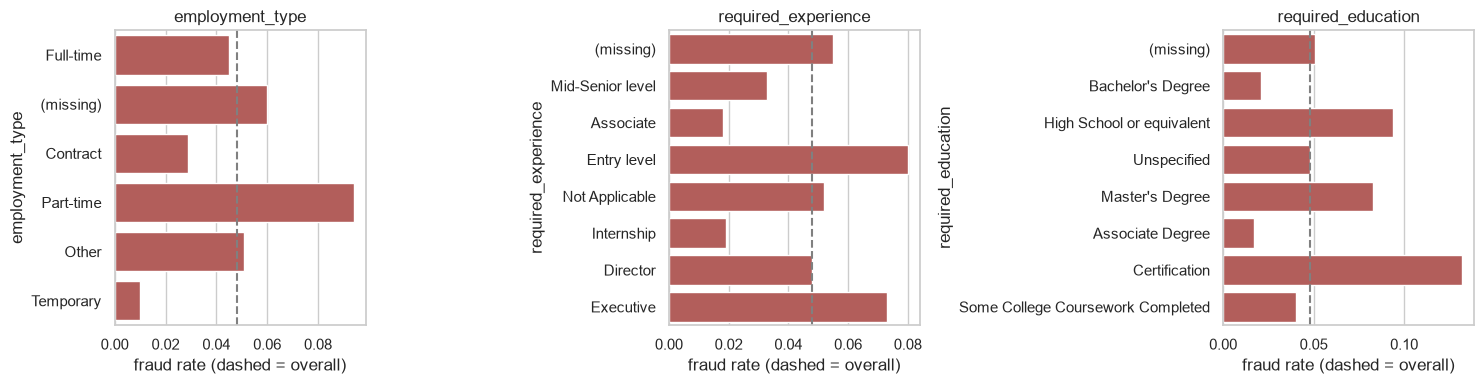

In [23]:
low_card = ["employment_type", "required_experience", "required_education"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, low_card):
    t = rate_table(col, min_n=30, top=8).reset_index()
    t[col] = t[col].fillna("(missing)").astype(str)
    sns.barplot(data=t, y=col, x="fraud_rate", color="#c0504d", ax=ax)
    ax.axvline(base_rate, color="gray", ls="--")
    ax.set_title(col)
    ax.set_xlabel("fraud rate (dashed = overall)")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_categorical_fraud_rates.png", dpi=200)
plt.show()

**What to look for**
- Which categories sit clearly above or below the dashed line, with a reasonable `n`?
- For high-cardinality fields (`industry`, `function`), only the larger categories are shown; the long tail is hidden. Think about how you would encode such a field for a model.

### 3.5 Binary flags

In [24]:
for col in d1.BINARY_COLS:
    t = train.groupby(col)[d1.TARGET].agg(n="size", fraud_n="sum", fraud_rate="mean").round(3)
    print(f"== {col} ==")
    display(t)

== telecommuting ==


,n,fraud_n,fraud_rate
telecommuting,,,
0,13808,634,0.046
1,631,59,0.094


== has_company_logo ==


,n,fraud_n,fraud_rate
has_company_logo,,,
0,3036,452,0.149
1,11403,241,0.021


== has_questions ==


,n,fraud_n,fraud_rate
has_questions,,,
0,7104,489,0.069
1,7335,204,0.028


**What to look for:** compare the fraud rate when the flag is 0 vs 1. A large ratio between the two rates means the flag separates the classes well. Remember that all three can overlap with each other (next section).

### 3.6 How related are the signals to each other?
Many "red flags" tend to appear together (no logo, no company profile, no screening questions). That matters later: when predictors are correlated, a model can split credit between them in arbitrary ways, so importance scores become hard to interpret. This is why the project tests signals with ablations rather than relying on importance scores alone.

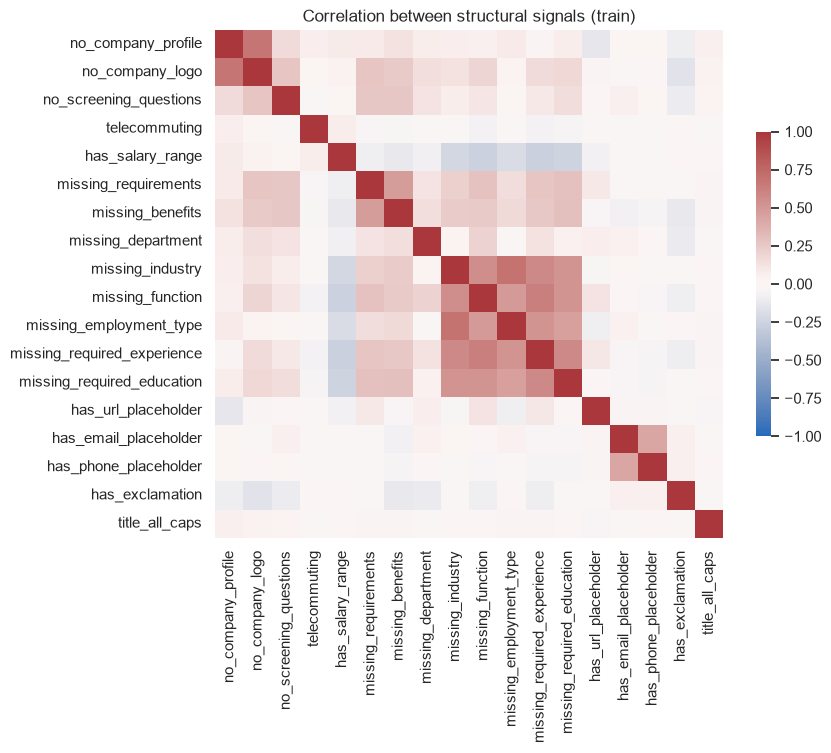

Pairs with |correlation| > 0.4:


correlation
missing_industry            missing_employment_type             0.69
no_company_profile          no_company_logo                     0.68
missing_function            missing_required_experience         0.63
missing_required_experience missing_required_education          0.57
missing_industry            missing_required_experience         0.57
                            missing_function                    0.55
missing_function            missing_required_education          0.52
missing_industry            missing_required_education          0.52
missing_employment_type     missing_required_experience         0.52
missing_function            missing_employment_type             0.49
missing_requirements        missing_benefits                    0.47
missing_employment_type     missing_required_education          0.46
has_email_placeholder       has_phone_placeholder               0.42

In [25]:
flags = d1.add_structural_flags(train)
corr = flags.astype(int).corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.6}, ax=ax)
ax.set_title("Correlation between structural signals (train)")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_signal_correlation.png", dpi=200)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print("Pairs with |correlation| > 0.4:")
display(pairs[pairs.abs() > 0.4].sort_values(ascending=False).round(2).to_frame("correlation"))

**What to look for:** which signals are strongly related to each other? Pairs near 1 carry almost the same information, so adding both to a model adds little over adding one.

### 3.7 Location

In [26]:
loc = (train.groupby("country")[d1.TARGET].agg(n="size", fraud_n="sum", fraud_rate="mean")
            .sort_values("n", ascending=False))
print(f"distinct countries: {loc.shape[0]} | share of rows with unknown location: {(train['country'] == 'UNK').mean():.1%}")
print(f"share of postings from the top country: {loc['n'].iloc[0] / len(train):.1%}\n")
display(loc.head(12).round(3))

distinct countries: 88 | share of rows with unknown location: 2.0%
share of postings from the top country: 57.1%



,n,fraud_n,fraud_rate
country,,,
US,8251,584,0.071
GB,1983,13,0.007
GR,816,0,0.000
CA,385,11,0.029
DE,360,0,0.000
UNK,291,16,0.055
NZ,288,0,0.000
IN,224,4,0.018
AU,184,30,0.163


**What to look for**
- How concentrated is the data in one or two countries? Strong concentration limits how far conclusions can be generalised and limits which countries can serve as hold-outs for robustness tests.
- How many countries have enough fraud postings (say 25 or more) to evaluate on?

### 3.8 Salary
`salary_range` is text. Check how often it is filled in and whether the values are really numeric ranges.

In [27]:
sal = train["salary_range"]
parsed = sal.str.extract(r"^\s*(\d+)\s*-\s*(\d+)\s*$").astype(float)
parsed.columns = ["sal_min", "sal_max"]
ok = parsed.notna().all(axis=1)

print(f"salary present: {sal.notna().mean():.1%} | parseable as 'min-max': {ok.mean():.1%} | present but odd format: {int((sal.notna() & ~ok).sum())}")
print("\nMost common values that are present but not a clean min-max:")
display(sal[sal.notna() & ~ok].value_counts().head(10).to_frame("count"))

print("Fraud rate by whether a salary is given:")
display(train.groupby(sal.notna())[d1.TARGET].agg(n="size", fraud_rate="mean").round(3).rename_axis("salary_present"))

print("Median parsed salary by class (parseable rows only):")
display(pd.concat([train[d1.TARGET], parsed], axis=1)[ok].groupby(d1.TARGET).median())

salary present: 16.3% | parseable as 'min-max': 16.2% | present but odd format: 23

Most common values that are present but not a clean min-max:


,count
salary_range,
10-Oct,6
10-Nov,5
Oct-20,2
11-Nov,2
4-Apr,1
Oct-15,1
8-Sep,1
Jun-18,1
11-Dec,1


Fraud rate by whether a salary is given:


,n,fraud_rate
salary_present,,
False,12082,0.043
True,2357,0.076


Median parsed salary by class (parseable rows only):


,sal_min,sal_max
fraudulent,,
0,35000.0,50000.0
1,30000.0,50000.0


**What to look for:** are there entries that are not numeric ranges (for example dates produced by a spreadsheet, or `0-0`)? Decide how you will clean them. Also check whether the parsed numbers look plausible: very small or huge values may be different currencies or monthly vs yearly amounts.

### 3.9 Masked contact details
EMSCAD replaces URLs, emails and phone numbers in the text with placeholders. Whether a posting contains one may be informative. First confirm that the placeholders exist in your copy.

In [28]:
for tag in ["#URL_", "#EMAIL_", "#PHONE_"]:
    has = train["text_all"].str.contains(tag, regex=False)
    print(f"{tag:8s} present in {has.mean():6.1%} of postings | fraud rate when present: {train.loc[has, d1.TARGET].mean():.3f} | when absent: {train.loc[~has, d1.TARGET].mean():.3f}")

#URL_    present in  33.8% of postings | fraud rate when present: 0.045 | when absent: 0.050
#EMAIL_  present in   7.8% of postings | fraud rate when present: 0.126 | when absent: 0.041
#PHONE_  present in   2.4% of postings | fraud rate when present: 0.201 | when absent: 0.044


**What to look for:** if all three show 0%, the placeholder format in your copy is different. Search a few descriptions manually for patterns like `#...#`, then update the regex in `d1.add_text_all` and `d1.add_structural_flags`.

### 3.10 Which words are common in each class?
This is only descriptive: the share of postings in each class that contain a word. A word being common in fraud postings does not mean it is a good red flag, because common words are common in both classes. Separating "common" from "different between classes" is what the next notebook does with weighted log-odds and a confirmation step.

In [29]:
cv = CountVectorizer(stop_words="english", min_df=20, binary=True, max_features=5000)
X = cv.fit_transform(train["text_clean"])
vocab = np.array(cv.get_feature_names_out())
is_fraud = (train[d1.TARGET] == 1).to_numpy()

freq = pd.DataFrame({
    "share_of_fraud_postings": np.asarray(X[is_fraud].mean(axis=0)).ravel(),
    "share_of_legit_postings": np.asarray(X[~is_fraud].mean(axis=0)).ravel(),
}, index=vocab)

print("Most common words in FRAUD postings:")
display(freq.sort_values("share_of_fraud_postings", ascending=False).head(15).round(3))
print("Most common words in LEGITIMATE postings:")
display(freq.sort_values("share_of_legit_postings", ascending=False).head(15).round(3))

Most common words in FRAUD postings:


,share_of_fraud_postings,share_of_legit_postings
work,0.759,0.721
experience,0.717,0.816
skills,0.613,0.551
company,0.511,0.558
time,0.476,0.516
team,0.452,0.688
amp,0.449,0.419
position,0.431,0.315
years,0.430,0.505
ability,0.392,0.381


Most common words in LEGITIMATE postings:


,share_of_fraud_postings,share_of_legit_postings
experience,0.717,0.816
work,0.759,0.721
team,0.452,0.688
company,0.511,0.558
skills,0.613,0.551
time,0.476,0.516
years,0.430,0.505
working,0.387,0.492
new,0.333,0.491
looking,0.326,0.460


**What to look for:** how much do the two lists overlap? Words that appear high on both lists are common everywhere and will not help a model separate the classes.

## 4. Your notes (answer in your own words)

These answers feed directly into the Data Overview and limitations sections of the report. Copy them into a text file or a new markdown cell.

1. How many postings and fields are there, and how many are fraudulent? Why is accuracy a misleading metric here?
2. What share of postings are in duplicate groups, and how many groups have conflicting labels? Why does this matter for evaluation?
3. Which fields are most often missing? Which show the biggest missingness gap between fraud and legitimate postings?
4. Which categorical values or binary flags have fraud rates well above or below the overall rate, with a reasonable sample size?
5. Which of the structural signals are strongly correlated with each other?
6. How concentrated is the data by country, and what does that imply for generalisation?
7. What problems did you find in the raw fields (odd salary formats, missing placeholders, free-text categories) and how will you clean them?
8. What are your first three hypotheses about what makes a posting fraudulent? How would you test each one?
9. What limitations of this dataset (age, geography, collection, label quality) should the report state?

**Next:** open `01_d1_eda.ipynb`. It reuses the same split and runs the formal hypothesis tests and the text-signal discovery.

In [30]:
from scipy.stats import fisher_exact

TAB_DIR = ROOT / "reports" / "tables"
TAB_DIR.mkdir(parents=True, exist_ok=True)
N_DRAWS = 200            # number of random "one posting per group" samples


def bh_adjust(p_values):
    """Benjamini-Hochberg adjusted p-values (q-values)."""
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order] * n / np.arange(1, n + 1)
    q_sorted = np.minimum(np.minimum.accumulate(ranked[::-1])[::-1], 1.0)
    q = np.empty(n)
    q[order] = q_sorted
    return q


def odds_ratio_table(flags, y, alpha=0.05):
    """Fisher's exact test and odds ratio (Woolf 95% CI) for every boolean column of `flags`."""
    y = pd.Series(y).astype(bool).to_numpy()
    rows = []
    for col in flags.columns:
        f = flags[col].astype(bool).to_numpy()
        a, b = int((f & y).sum()), int((f & ~y).sum())      # flagged: fraud, legit
        c, d = int((~f & y).sum()), int((~f & ~y).sum())    # not flagged: fraud, legit
        _, p = fisher_exact([[a, b], [c, d]])
        a2, b2, c2, d2 = a + 0.5, b + 0.5, c + 0.5, d + 0.5
        odds = (a2 * d2) / (b2 * c2)
        se = np.sqrt(1 / a2 + 1 / b2 + 1 / c2 + 1 / d2)
        rows.append({
            "feature": col,
            "n_flagged": a + b,
            "fraud_rate_flagged": a / (a + b) if (a + b) else np.nan,
            "fraud_rate_unflagged": c / (c + d) if (c + d) else np.nan,
            "odds_ratio": odds,
            "ci_low": float(np.exp(np.log(odds) - 1.96 * se)),
            "ci_high": float(np.exp(np.log(odds) + 1.96 * se)),
            "p_value": p,
        })
    out = pd.DataFrame(rows)
    out["q_value_bh"] = bh_adjust(out["p_value"])
    out["significant"] = out["q_value_bh"] < alpha
    return out.sort_values("p_value").reset_index(drop=True)


def repeated_tests(flags, y, groups, n_draws=N_DRAWS, seed=SEED):
    """Repeat the tests on random samples that keep ONE posting per group, then summarise.

    Rows in the same group are copies of one template, so counting each of them would overstate
    the evidence. Each draw gives every group a single vote; the draws show how stable the result is.
    """
    flags = flags.reset_index(drop=True)
    y = np.asarray(y)
    groups = np.asarray(groups)
    rng = np.random.default_rng(seed)
    tables = []
    for d in range(n_draws):
        perm = rng.permutation(len(groups))
        _, first = np.unique(groups[perm], return_index=True)   # first row of each group in a random order
        pick = perm[first]
        tables.append(odds_ratio_table(flags.iloc[pick], y[pick]))
    allt = pd.concat(tables)
    return allt.groupby("feature").agg(
        n_flagged=("n_flagged", "median"),
        fraud_rate_flagged=("fraud_rate_flagged", "median"),
        fraud_rate_unflagged=("fraud_rate_unflagged", "median"),
        or_median=("odds_ratio", "median"),
        ci_low=("ci_low", "median"),
        ci_high=("ci_high", "median"),
        p_median=("p_value", "median"),
        q_median=("q_value_bh", "median"),
        frac_sig=("significant", "mean"),
    )

,n_flagged_all_rows,OR_all_rows,p_all_rows,OR_one_per_group,CI_low,CI_high,q_one_per_group,share_of_draws_significant
feature,,,,,,,,
no_company_logo,3036,8.0926,0.0000,7.6301,5.4885,10.6073,0.0000,1.000
no_company_profile,2631,10.3670,0.0000,5.4214,3.8461,7.6420,0.0000,1.000
country_US,8251,4.2324,0.0000,2.9587,2.2701,3.8561,0.0000,1.000
no_screening_questions,7104,2.5803,0.0000,2.9720,2.2724,3.8884,0.0000,1.000
missing_required_experience,6010,1.3069,0.0007,1.8556,1.4776,2.3303,0.0000,1.000
has_phone_placeholder,353,5.4744,0.0000,4.0191,2.5446,6.3492,0.0000,1.000
has_email_placeholder,1122,3.3310,0.0000,2.3795,1.6885,3.3576,0.0000,1.000
has_exclamation,4665,1.0511,0.5602,0.5865,0.4376,0.7862,0.0004,1.000
missing_required_education,6764,1.1385,0.1013,1.5249,1.2116,1.9193,0.0007,1.000


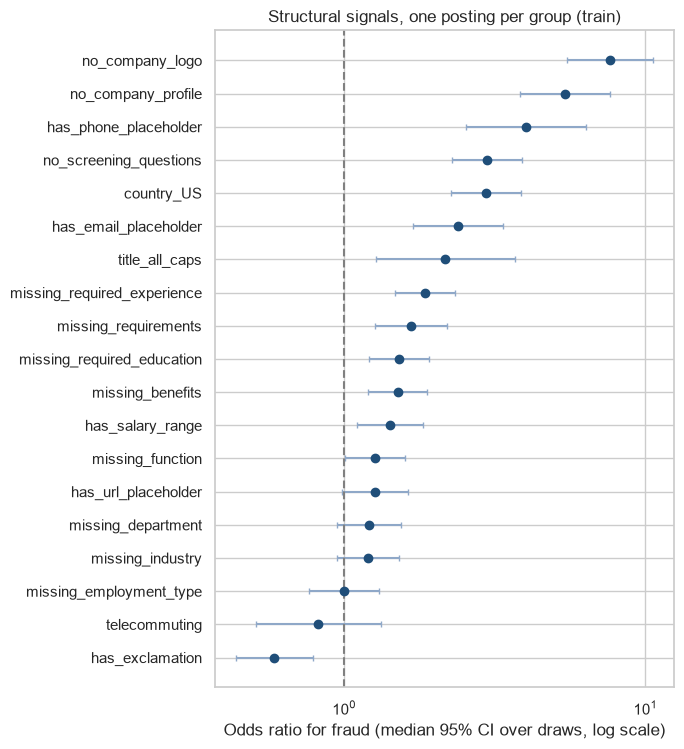

In [35]:
y = train[d1.TARGET].to_numpy()
groups = train["group_id"].to_numpy()

flags = d1.add_structural_flags(train)          # yes/no signals chosen from domain knowledge
flags["country_US"] = (train["country"] == "US").to_numpy()

naive = odds_ratio_table(flags, y).set_index("feature")      # every row counts (overstates the evidence)
summ = repeated_tests(flags, y, groups)                      # one posting per group, 200 random draws

compare = pd.DataFrame({
    "n_flagged_all_rows": naive["n_flagged"],
    "OR_all_rows": naive["odds_ratio"],
    "p_all_rows": naive["p_value"],
    "OR_one_per_group": summ["or_median"],
    "CI_low": summ["ci_low"],
    "CI_high": summ["ci_high"],
    "q_one_per_group": summ["q_median"],
    "share_of_draws_significant": summ["frac_sig"],
}).sort_values("q_one_per_group")
display(compare.round(4))
summ.to_csv(TAB_DIR / "structural_tests_one_per_group.csv")

plot = summ.sort_values("or_median")
fig, ax = plt.subplots(figsize=(7, 0.35 * len(plot) + 1))
ax.errorbar(plot["or_median"], range(len(plot)),
            xerr=[plot["or_median"] - plot["ci_low"], plot["ci_high"] - plot["or_median"]],
            fmt="o", color="#1f4e79", ecolor="#8fa8c8", capsize=2)
ax.axvline(1, color="gray", ls="--")
ax.set_xscale("log")
ax.set_yticks(range(len(plot)))
ax.set_yticklabels(plot.index)
ax.set_xlabel("Odds ratio for fraud (median 95% CI over draws, log scale)")
ax.set_title("Structural signals, one posting per group (train)")
plt.tight_layout()
plt.savefig(FIG_DIR / "structural_odds_ratios.png", dpi=200, bbox_inches="tight")
plt.show()

In [36]:
extra = {}
for col in ["employment_type", "required_experience", "required_education", "function", "industry"]:
    vc = train[col].value_counts()
    for lvl in vc[vc >= 100].index:                     # only levels with enough postings
        extra[f"{col}={lvl}"] = (train[col] == lvl).to_numpy()

for col in ["description", "requirements"]:             # "short" = bottom quartile among non-empty
    w = train[col].fillna("").str.split().str.len()
    extra[f"short_{col}"] = ((w > 0) & (w <= w[w > 0].quantile(0.25))).to_numpy()

for c in ["US", "GB", "AU"]:
    extra[f"country={c}"] = (train["country"] == c).to_numpy()

extra = pd.DataFrame(extra, index=train.index)
summ_extra = repeated_tests(extra, y, groups)
display(summ_extra.sort_values("q_median")[["n_flagged", "fraud_rate_flagged", "fraud_rate_unflagged",
                                            "or_median", "ci_low", "ci_high", "q_median", "frac_sig"]].round(4))
summ_extra.to_csv(TAB_DIR / "extra_tests_one_per_group.csv")

# For the joint model in cell 3, add this line right after `flags = d1.add_structural_flags(train)`:
# flags["country_US"] = (train["country"] == "US").to_numpy()

,n_flagged,fraud_rate_flagged,fraud_rate_unflagged,or_median,ci_low,ci_high,q_median,frac_sig
feature,,,,,,,,
function=Administrative,136.0,0.4213,0.0794,8.4559,5.8926,12.1068,0.0000,1.000
industry=Accounting,50.0,0.6735,0.0842,22.0654,12.0927,40.2625,0.0000,1.000
industry=Oil & Energy,41.0,0.7073,0.0854,25.2453,12.8929,49.4322,0.0000,1.000
required_education=Bachelor's Degree,895.0,0.0234,0.1158,0.1863,0.1195,0.2904,0.0000,1.000
country=US,1959.0,0.1291,0.0476,2.9587,2.2701,3.8561,0.0000,1.000
required_experience=Mid-Senior level,845.0,0.0308,0.1118,0.2567,0.1713,0.3848,0.0000,1.000
country=AU,64.0,0.4062,0.0868,7.2312,4.3487,12.0245,0.0000,1.000
required_experience=Associate,411.0,0.0195,0.1020,0.1858,0.0933,0.3701,0.0000,1.000
required_education=High School or equivalent,253.0,0.2158,0.0831,3.0526,2.2131,4.2185,0.0000,1.000


In [37]:
try:
    import statsmodels.api as sm
except ImportError:
    sm = None
    print("statsmodels is not installed. Run:  pip install statsmodels   then restart the kernel.")

if sm is not None:
    # Signals that are very rare (or almost always present) cannot be estimated reliably in a joint model
    keep = [c for c in flags.columns if flags[c].sum() >= 30 and (~flags[c]).sum() >= 30]
    print("left out of the joint model (too rare):", [c for c in flags.columns if c not in keep])

    X = sm.add_constant(flags[keep].astype(float))
    gcodes = pd.factorize(groups)[0]
    try:
        # Logistic regression with standard errors that allow for postings within a group being alike
        fit = sm.Logit(y, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": gcodes})
        ci = fit.conf_int()
        adj = pd.DataFrame({
            "adjusted_OR": np.exp(fit.params),
            "ci_low": np.exp(ci[0]),
            "ci_high": np.exp(ci[1]),
            "p_value": fit.pvalues,
        }).drop(index="const")
        adj["q_value_bh"] = bh_adjust(adj["p_value"])
        adj["univariate_OR"] = summ["or_median"].reindex(adj.index)
        display(adj.sort_values("p_value").round(4))
        adj.to_csv(TAB_DIR / "structural_joint_model.csv")
    except Exception as exc:
        print("The joint model did not converge:", type(exc).__name__, "-", exc)

left out of the joint model (too rare): []


,adjusted_OR,ci_low,ci_high,p_value,q_value_bh,univariate_OR
country_US,4.3504,2.8561,6.6266,0.0000,0.0000,2.9587
no_company_profile,5.5466,2.7933,11.0138,0.0000,0.0000,5.4214
has_email_placeholder,3.3728,1.8211,6.2467,0.0001,0.0007,2.3795
no_company_logo,2.3803,1.3012,4.3545,0.0049,0.0232,7.6301
missing_requirements,0.5175,0.3197,0.8377,0.0074,0.0252,1.6636
missing_required_experience,2.1829,1.2264,3.8854,0.0080,0.0252,1.8556
missing_department,0.5446,0.3336,0.8891,0.0151,0.0410,1.2096
no_screening_questions,1.7592,1.0678,2.8982,0.0266,0.0631,2.9720
title_all_caps,2.5533,1.0850,6.0087,0.0318,0.0672,2.1690
missing_industry,0.5612,0.3034,1.0379,0.0656,0.1246,1.2009


In [34]:
import html


def log_odds_dirichlet(fraud_texts, legit_texts, ngram_range=(1, 2), min_df=5, alpha0=500.0):
    """Rank words and 2-word phrases by how much they favour fraud (positive z) or legitimate (negative z).
    Weighted log-odds with an informative Dirichlet prior (Monroe, Colaresi and Quinn, 2008)."""
    fraud_texts, legit_texts = list(fraud_texts), list(legit_texts)
    nf = len(fraud_texts)
    vec = CountVectorizer(ngram_range=ngram_range, min_df=min_df, lowercase=True)
    X = vec.fit_transform(fraud_texts + legit_texts)
    y_f = np.asarray(X[:nf].sum(axis=0)).ravel().astype(float)
    y_l = np.asarray(X[nf:].sum(axis=0)).ravel().astype(float)
    docs = (X > 0).astype(int)
    docs_f = np.asarray(docs[:nf].sum(axis=0)).ravel()
    docs_l = np.asarray(docs[nf:].sum(axis=0)).ravel()
    prior = y_f + y_l
    alpha = alpha0 * prior / prior.sum()
    n_f, n_l = y_f.sum(), y_l.sum()
    delta = (np.log((y_f + alpha) / (n_f + alpha0 - y_f - alpha))
             - np.log((y_l + alpha) / (n_l + alpha0 - y_l - alpha)))
    var = 1.0 / (y_f + alpha) + 1.0 / (y_l + alpha)
    out = pd.DataFrame({"term": vec.get_feature_names_out(), "fraud_docs": docs_f, "legit_docs": docs_l,
                        "fraud_doc_rate": docs_f / max(nf, 1), "legit_doc_rate": docs_l / max(len(legit_texts), 1),
                        "log_odds": delta, "z": delta / np.sqrt(var)})
    return out.sort_values("z", ascending=False).reset_index(drop=True)


def term_flags(texts, terms, ngram_range=(1, 2)):
    """Yes/no table: does each text contain each term? Uses the same tokenizer as the mining step."""
    terms = list(terms)
    texts = pd.Series(texts).fillna("").astype(str)
    vec = CountVectorizer(vocabulary=terms, ngram_range=ngram_range, lowercase=True, binary=True)
    X = vec.transform(texts)
    return pd.DataFrame(X.toarray().astype(bool), columns=[f"kw::{t}" for t in terms], index=texts.index)


def one_per_group(positions, seed):
    """Pick one random row per group from the given row positions."""
    rng = np.random.default_rng(seed)
    perm = rng.permutation(positions)
    _, first = np.unique(groups[perm], return_index=True)
    return perm[first]


# Text used for mining: HTML entities decoded ("&amp;" -> "&"), URLs/emails/phones already replaced by tokens
text_mine = train["text_clean"].map(html.unescape).to_numpy()

# 1) Split the TRAIN groups into two halves: discovery (find candidate phrases) and confirmation (test them)
sgkf = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED)
disc_idx, conf_idx = next(sgkf.split(train, y, groups=groups))
assert set(groups[disc_idx]).isdisjoint(groups[conf_idx])

# 2) Discovery: rank phrases using one posting per group, so one template does not dominate
disc_pick = one_per_group(disc_idx, SEED)
fraud_docs = text_mine[disc_pick][y[disc_pick] == 1]
legit_docs = text_mine[disc_pick][y[disc_pick] == 0]
print(f"discovery: {len(disc_pick)} postings (one per group) | fraud {len(fraud_docs)} | legitimate {len(legit_docs)}")

terms = log_odds_dirichlet(fraud_docs, legit_docs, min_df=5)
print("Top fraud-leaning phrases (discovery):")
display(terms.head(30).round(3))
print("Top legitimate-leaning phrases (discovery):")
display(terms.tail(20).iloc[::-1].round(3))

# 3) Confirmation: test the top candidates on the OTHER half, again one posting per group
TOP_K = 50
candidates = terms.head(TOP_K)["term"].tolist()
conf_flags = term_flags(text_mine[conf_idx], candidates)
conf_summ = repeated_tests(conf_flags, y[conf_idx], groups[conf_idx])
conf_summ.index = conf_summ.index.str.replace("kw::", "", regex=False)

confirmed = conf_summ[(conf_summ["or_median"] > 1) & (conf_summ["q_median"] < 0.05)].sort_values("or_median", ascending=False)
print(f"{len(confirmed)} of {TOP_K} candidate phrases confirmed on the held-out half (odds ratio > 1 and BH q < 0.05)")
display(confirmed.round(4))

conf_summ.to_csv(TAB_DIR / "lexicon_candidates_tested.csv")
confirmed.to_csv(TAB_DIR / "lexicon_confirmed.csv")

discovery: 1778 postings (one per group) | fraud 164 | legitimate 1614
Top fraud-leaning phrases (discovery):


,term,fraud_docs,legit_docs,fraud_doc_rate,legit_doc_rate,log_odds,z
0,administrative,34,61,0.207,0.038,2.215,14.157
1,assistant,33,72,0.201,0.045,1.837,12.089
2,data entry,21,17,0.128,0.011,2.987,11.938
3,entry,26,66,0.159,0.041,1.948,11.103
4,hotel,9,19,0.055,0.012,2.017,9.599
5,gas,12,19,0.073,0.012,2.455,9.561
6,patient,13,33,0.079,0.020,2.091,9.535
7,administrative assistant,17,7,0.104,0.004,3.269,9.186
8,lean,6,29,0.037,0.018,2.117,8.526
9,receptionist,12,4,0.073,0.002,3.165,8.359


Top legitimate-leaning phrases (discovery):


,term,fraud_docs,legit_docs,fraud_doc_rate,legit_doc_rate,log_odds,z
20406,our,70,1077,0.427,0.667,-0.700,-8.746
20405,you,65,937,0.396,0.581,-0.544,-7.696
20404,we,93,1100,0.567,0.682,-0.410,-6.416
20403,web,8,420,0.049,0.260,-2.132,-6.242
20402,marketing,12,371,0.073,0.230,-1.314,-6.206
20401,new,36,717,0.220,0.444,-0.738,-5.231
20400,re,17,365,0.104,0.226,-1.083,-5.085
20399,you will,19,487,0.116,0.302,-1.001,-5.000
20398,media,4,254,0.024,0.157,-2.126,-4.919
20397,software,16,485,0.098,0.300,-0.815,-4.797


33 of 50 candidate phrases confirmed on the held-out half (odds ratio > 1 and BH q < 0.05)


,n_flagged,fraud_rate_flagged,fraud_rate_unflagged,or_median,ci_low,ci_high,p_median,q_median,frac_sig
feature,,,,,,,,,
apply using,7.0,0.8571,0.0893,44.0852,7.4130,262.1757,0.0000,0.0000,1.000
appraisal,5.0,0.8000,0.0903,30.1402,4.7155,192.6495,0.0003,0.0007,1.000
oil and,11.0,0.7273,0.0883,24.9918,7.1204,87.7181,0.0000,0.0000,1.000
clerical,21.0,0.6667,0.0855,20.6372,8.4135,50.6202,0.0000,0.0000,1.000
bottom line,14.0,0.6429,0.0879,17.8670,6.1717,51.7251,0.0000,0.0000,1.000
and gas,11.0,0.6364,0.0889,17.0317,5.2329,55.4343,0.0000,0.0000,1.000
administrative assistant,21.0,0.6190,0.0860,16.8311,7.0217,40.3444,0.0000,0.0000,1.000
data entry,37.0,0.5946,0.0817,16.2835,8.3097,31.7992,0.0000,0.0000,1.000
receptionist,19.0,0.6111,0.0870,16.0476,6.3019,40.8647,0.0000,0.0000,1.000


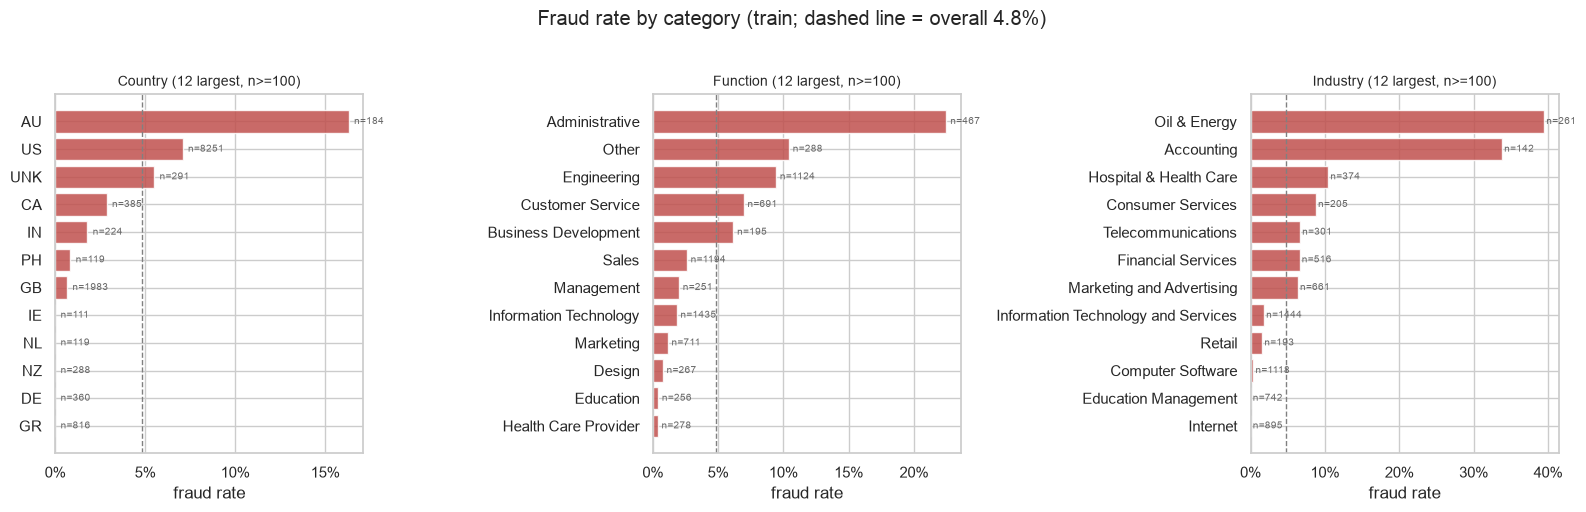

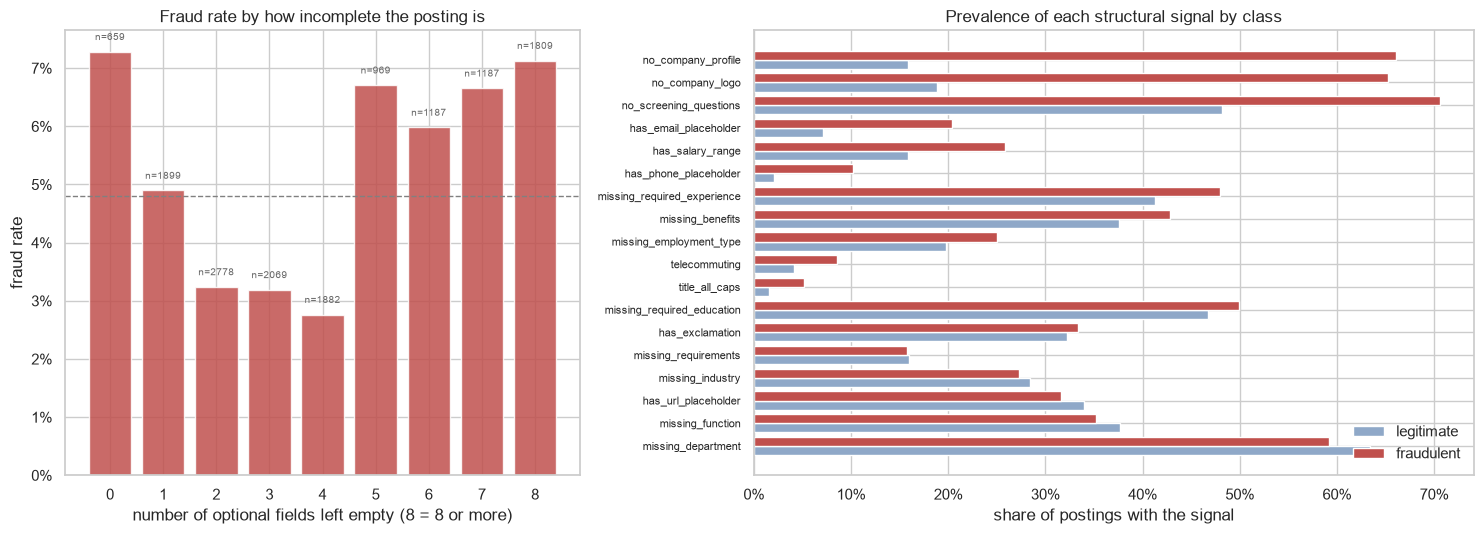

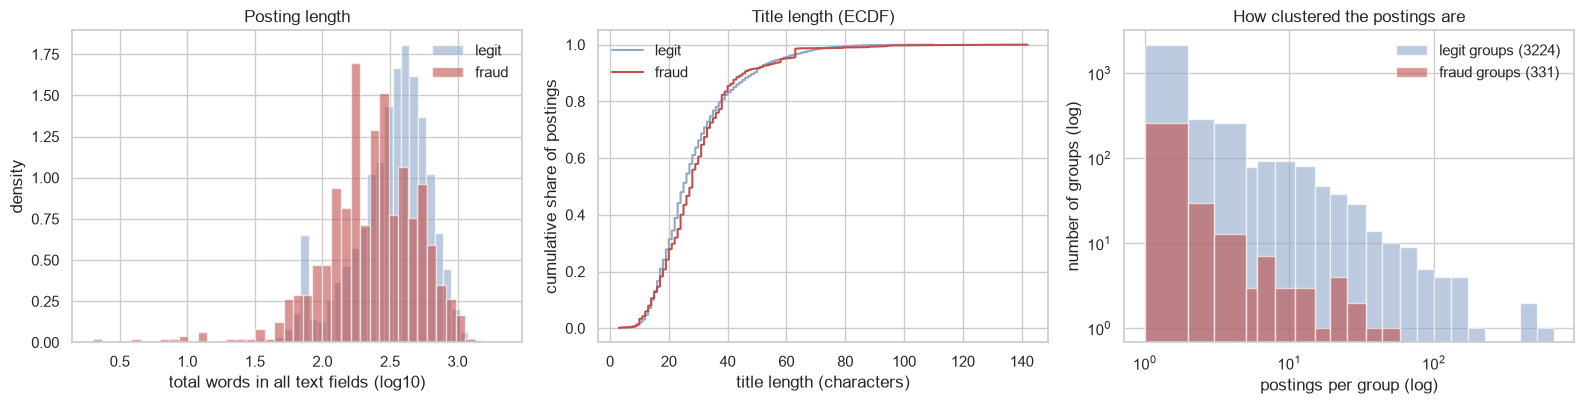

              count   mean    std  min    25%    50%    75%     max
fraudulent                                                         
fraud         693.0  298.0  210.0  2.0  145.0  245.0  408.0  1338.0
legit       13746.0  379.0  211.0  7.0  231.0  355.0  498.0  2118.0


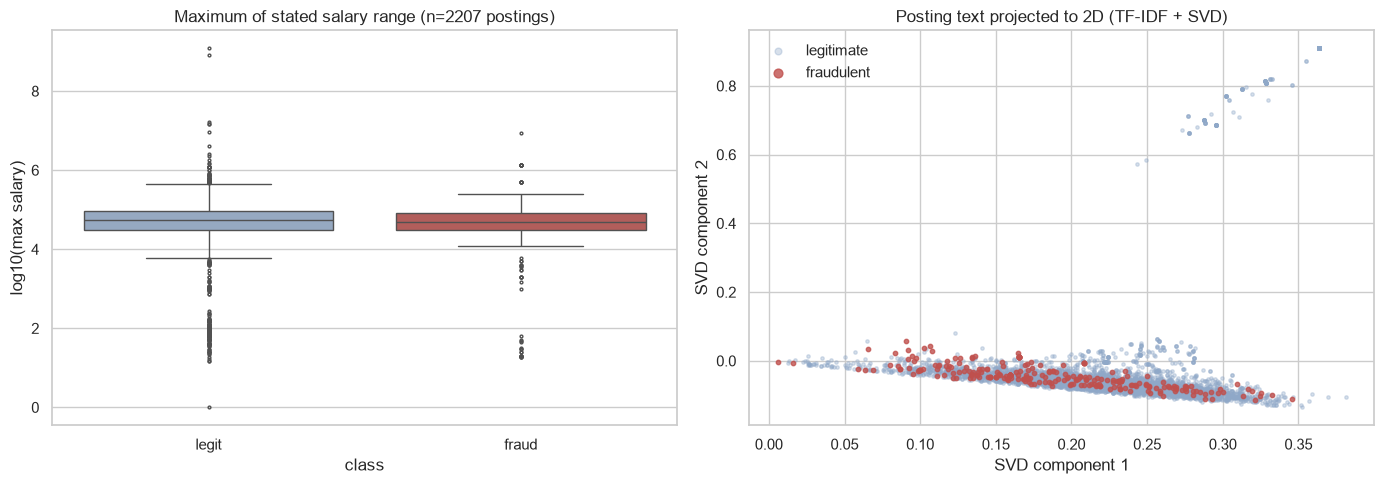

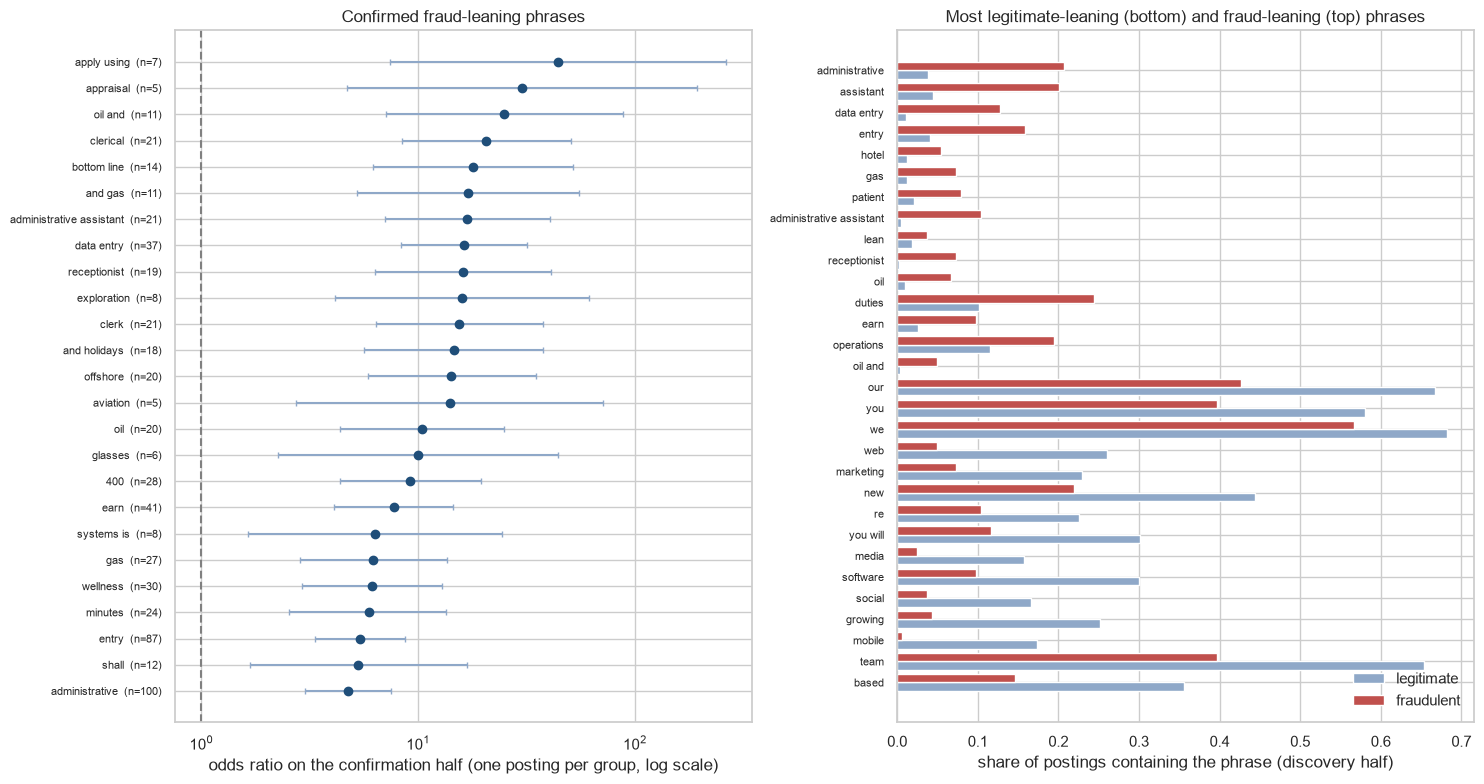

In [38]:
# Paste each block below into its own notebook cell (blocks are separated by '# %%').
# Run them after the split cell: they need `train`, `d1`, `FIG_DIR`, `SEED`, `plt`, `sns`, `np`, `pd`.

# %% Figure 1: fraud rate by country, function and industry
PAL = {"legit": "#8fa8c8", "fraud": "#c0504d"}
base = train[d1.TARGET].mean()


def rate_bars(ax, col, min_n=50, top=12, title=None):
    t = (train.groupby(col)[d1.TARGET].agg(n="size", fraud_n="sum", fraud_rate="mean")
              .query("n >= @min_n").sort_values("n", ascending=False).head(top)
              .sort_values("fraud_rate"))
    ax.barh(t.index.astype(str), t["fraud_rate"], color=PAL["fraud"], alpha=0.85)
    ax.axvline(base, color="gray", ls="--", lw=1)
    for i, (r, n) in enumerate(zip(t["fraud_rate"], t["n"])):
        ax.text(r + 0.003, i, f"n={n}", va="center", fontsize=7, color="dimgray")
    ax.set_xlabel("fraud rate")
    ax.set_title(title or col, fontsize=10)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))


fig, axes = plt.subplots(1, 3, figsize=(16, 5))
rate_bars(axes[0], "country", min_n=100, top=12, title="Country (12 largest, n>=100)")
rate_bars(axes[1], "function", min_n=100, top=12, title="Function (12 largest, n>=100)")
rate_bars(axes[2], "industry", min_n=100, top=12, title="Industry (12 largest, n>=100)")
fig.suptitle(f"Fraud rate by category (train; dashed line = overall {base:.1%})", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "fraud_rate_by_category.png", dpi=200, bbox_inches="tight")
plt.show()

# %% Figure 2: completeness and structural-signal prevalence
# How much of the posting is filled in, and which structural signals are more common in fraud
opt_cols = ["department", "salary_range", "company_profile", "requirements", "benefits",
            "employment_type", "required_experience", "required_education", "industry", "function"]
n_missing = train[opt_cols].isna().sum(axis=1)
t = (train.assign(n_missing=n_missing.clip(upper=8))
          .groupby("n_missing")[d1.TARGET].agg(n="size", fraud_rate="mean"))

flags_v = d1.add_structural_flags(train)
prev = pd.DataFrame({"legit": flags_v[train[d1.TARGET] == 0].mean(),
                     "fraud": flags_v[train[d1.TARGET] == 1].mean()})
prev["gap"] = prev["fraud"] - prev["legit"]
prev = prev.sort_values("gap")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.bar(t.index.astype(str), t["fraud_rate"], color=PAL["fraud"], alpha=0.85)
for x, (r, n) in enumerate(zip(t["fraud_rate"], t["n"])):
    ax.text(x, r + 0.002, f"n={n}", ha="center", fontsize=7, color="dimgray")
ax.axhline(base, color="gray", ls="--", lw=1)
ax.set_xlabel("number of optional fields left empty (8 = 8 or more)")
ax.set_ylabel("fraud rate")
ax.set_title("Fraud rate by how incomplete the posting is")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))

ax = axes[1]
y_pos = np.arange(len(prev))
ax.barh(y_pos - 0.2, prev["legit"], height=0.4, color=PAL["legit"], label="legitimate")
ax.barh(y_pos + 0.2, prev["fraud"], height=0.4, color=PAL["fraud"], label="fraudulent")
ax.set_yticks(y_pos)
ax.set_yticklabels(prev.index, fontsize=8)
ax.set_xlabel("share of postings with the signal")
ax.set_title("Prevalence of each structural signal by class")
ax.legend(frameon=False, loc="lower right")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
plt.tight_layout()
plt.savefig(FIG_DIR / "completeness_and_signal_prevalence.png", dpi=200, bbox_inches="tight")
plt.show()

# %% Figure 3: length distributions and group sizes
# Length distributions and how clustered the data is
words_total = train["text_clean"].str.split().str.len()
title_len = train["title"].fillna("").str.len()
cls = train[d1.TARGET].map({0: "legit", 1: "fraud"})

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

ax = axes[0]
for name in ["legit", "fraud"]:
    v = np.log10(words_total[cls == name].clip(lower=1))
    ax.hist(v, bins=40, density=True, alpha=0.6, color=PAL[name], label=name)
ax.set_xlabel("total words in all text fields (log10)")
ax.set_ylabel("density")
ax.set_title("Posting length")
ax.legend(frameon=False)

ax = axes[1]
for name in ["legit", "fraud"]:
    v = np.sort(title_len[cls == name].to_numpy())
    ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=PAL[name], label=name)
ax.set_xlabel("title length (characters)")
ax.set_ylabel("cumulative share of postings")
ax.set_title("Title length (ECDF)")
ax.legend(frameon=False)

ax = axes[2]
gs = train.groupby("group_id").agg(size=("job_id", "size"), fraud=(d1.TARGET, "max"))
bins = np.unique(np.logspace(0, np.log10(gs["size"].max() + 1), 25).astype(int))
for lab, name in [(0, "legit"), (1, "fraud")]:
    ax.hist(gs.loc[gs["fraud"] == lab, "size"], bins=bins, alpha=0.6, color=PAL[name],
            label=f"{name} groups ({(gs['fraud'] == lab).sum()})")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("postings per group (log)")
ax.set_ylabel("number of groups (log)")
ax.set_title("How clustered the postings are")
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(FIG_DIR / "length_and_group_size.png", dpi=200, bbox_inches="tight")
plt.show()
print(words_total.groupby(cls).describe().round(0).to_string())

# %% Figure 4: salary and 2D text map
# Salary and a 2D map of the text
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Salary (only the 16% of rows with a clean "min-max" value)
parsed = train["salary_range"].str.extract(r"^\s*(\d+)\s*-\s*(\d+)\s*$").astype(float)
ok = parsed.notna().all(axis=1) & (parsed[1] > 0)
sal = pd.DataFrame({"log10_max_salary": np.log10(parsed.loc[ok, 1]),
                    "class": train.loc[ok, d1.TARGET].map({0: "legit", 1: "fraud"})})
ax = axes[0]
sns.boxplot(data=sal, x="class", y="log10_max_salary", order=["legit", "fraud"], hue="class", palette=PAL, legend=False, ax=ax, fliersize=2)
ax.set_title(f"Maximum of stated salary range (n={len(sal)} postings)")
ax.set_ylabel("log10(max salary)")

# 2D map of text: unsupervised, so it uses no labels in the layout. Fit on train only.
rng = np.random.default_rng(SEED)
pick = rng.choice(len(train), size=min(5000, len(train)), replace=False)
txt = train["text_clean"].iloc[pick].str.lower()
X = TfidfVectorizer(stop_words="english", min_df=5, max_df=0.5, sublinear_tf=True).fit_transform(txt)
xy = TruncatedSVD(n_components=2, random_state=SEED).fit_transform(X)
lab = train[d1.TARGET].iloc[pick].to_numpy()
ax = axes[1]
ax.scatter(xy[lab == 0, 0], xy[lab == 0, 1], s=6, alpha=0.35, color=PAL["legit"], label="legitimate")
ax.scatter(xy[lab == 1, 0], xy[lab == 1, 1], s=10, alpha=0.8, color=PAL["fraud"], label="fraudulent")
ax.set_xlabel("SVD component 1")
ax.set_ylabel("SVD component 2")
ax.set_title("Posting text projected to 2D (TF-IDF + SVD)")
ax.legend(frameon=False, markerscale=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "salary_and_text_map.png", dpi=200, bbox_inches="tight")
plt.show()

# %% Figure 5: lexicon results (run AFTER the lexicon cell)
# Results figures. Run after the hypothesis-test cells (needs `confirmed` and `terms`).
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

ax = axes[0]
c = confirmed.sort_values("or_median").tail(25)
ax.errorbar(c["or_median"], range(len(c)),
            xerr=[c["or_median"] - c["ci_low"], c["ci_high"] - c["or_median"]],
            fmt="o", color="#1f4e79", ecolor="#8fa8c8", capsize=2)
ax.axvline(1, color="gray", ls="--")
ax.set_xscale("log")
ax.set_yticks(range(len(c)))
ax.set_yticklabels([f"{t}  (n={int(n)})" for t, n in zip(c.index, c["n_flagged"])], fontsize=8)
ax.set_xlabel("odds ratio on the confirmation half (one posting per group, log scale)")
ax.set_title("Confirmed fraud-leaning phrases")

ax = axes[1]
top = terms.head(15).iloc[::-1]
bot = terms.tail(15)
show = pd.concat([bot, top])
y_pos = np.arange(len(show))
ax.barh(y_pos - 0.2, show["legit_doc_rate"], height=0.4, color=PAL["legit"], label="legitimate")
ax.barh(y_pos + 0.2, show["fraud_doc_rate"], height=0.4, color=PAL["fraud"], label="fraudulent")
ax.set_yticks(y_pos)
ax.set_yticklabels(show["term"], fontsize=8)
ax.set_xlabel("share of postings containing the phrase (discovery half)")
ax.set_title("Most legitimate-leaning (bottom) and fraud-leaning (top) phrases")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "lexicon_results.png", dpi=200, bbox_inches="tight")
plt.show()